In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
m = pd.read_csv('vizs1_service - vizs1_service.csv')
w = pd.read_csv('vizs1_waterpoints - vizs1_waterpoints.csv')
p = pd.read_csv('vizs1_pressure - vizs1_pressure.csv')
c = pd.read_csv('vizs1_projects - vizs1_projects.csv')
print(m.shape, w.shape, p.shape, c.shape)

(72, 9) (300, 11) (432, 10) (120, 9)


In [3]:
m['month'] = pd.to_datetime(m['month'])
c['week_start'] = pd.to_datetime(
c['week_start'])
trend = m.groupby('month', as_index=False)[
'delivered_m3'].sum()
print(len(trend))
print(trend['delivered_m3']
.iloc[[0,-1]].tolist())

12
[331600, 356971]


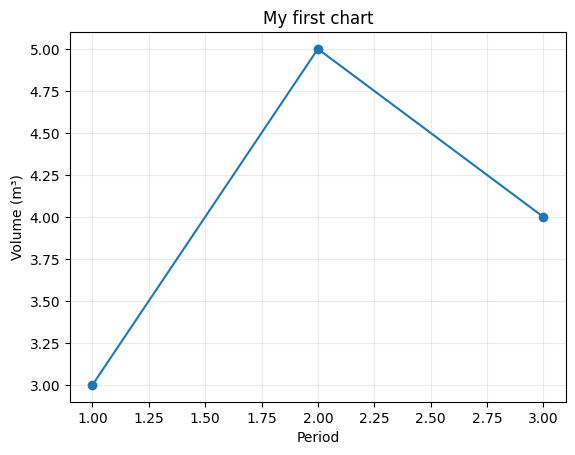

In [4]:
fig, ax = plt.subplots()
ax.plot([1, 2, 3], [3, 5, 4], marker='o')
ax.set(title='My first chart',
       xlabel='Period',
       ylabel='Volume (m³)')
ax.grid(alpha=0.25)
plt.show()

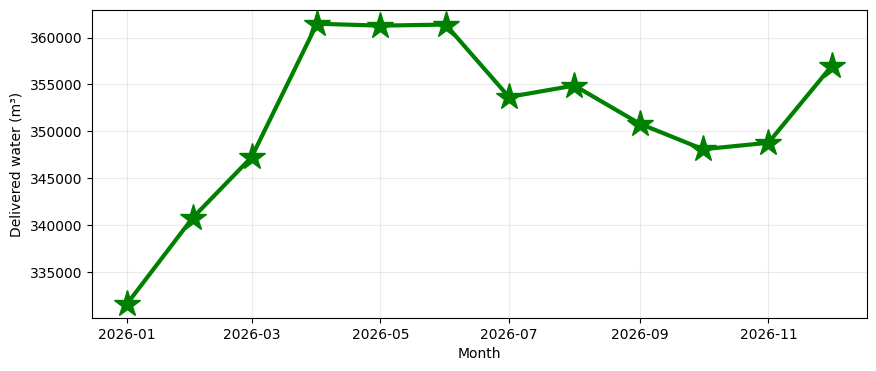

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trend['month'],
trend['delivered_m3'],
marker='*', linewidth=3,color='green',markersize=20)
ax.set(xlabel='Month',ylabel='Delivered water (m³)')
ax.grid(alpha=0.25)
plt.show()

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

np.random.seed(42)
# Create sample water utility dataset

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

districts = [
    "Bole", "Yeka", "Arada", "Kirkos",
    "Gullele", "Nifas Silk", "Kolfe", "Akaki"
]

data = pd.DataFrame({
    "Month": months,
    "Production": [120, 125, 130, 128, 135, 140,
                   138, 145, 142, 150, 148, 155],
    "Distribution": [105, 108, 112, 110, 115, 120,
                     118, 125, 122, 130, 128, 135],
    "Revenue": [8, 8.5, 9, 8.8, 9.5, 10,
                9.8, 10.5, 10.2, 11, 10.8, 12],
    "Target": [95] * 12
})

district_data = pd.DataFrame({
    "District": districts,
    "Production": [150, 130, 110, 125, 100, 115, 90, 105],
    "Consumption": [120, 105, 90, 100, 82, 95, 70, 85],
    "Customers": [50000, 42000, 35000, 40000,
                  30000, 38000, 25000, 32000],
    "NRW": [20, 19, 18, 20, 18, 17, 22, 19]
})

# Generate individual customer consumption records
customer_consumption = np.random.normal(15, 5, 500)
customer_consumption = np.clip(customer_consumption, 1, 35)

# Generate water pressure readings
pressure = np.random.normal(45, 8, 100)
pressure = np.clip(pressure, 15, 70)

# Generate daily data
daily_dates = pd.date_range("2026-01-01", periods=30)

daily_data = pd.DataFrame({
    "Date": daily_dates,
    "Production": np.random.randint(100, 160, 30),
    "Distribution": np.random.randint(80, 140, 30)
})

# Generate operational financial data
financial_data = {
    "Opening Balance": 100,
    "Collections": 75,
    "Adjustments": -10,
    "Refunds": -5,
    "Closing Balance": 160
}

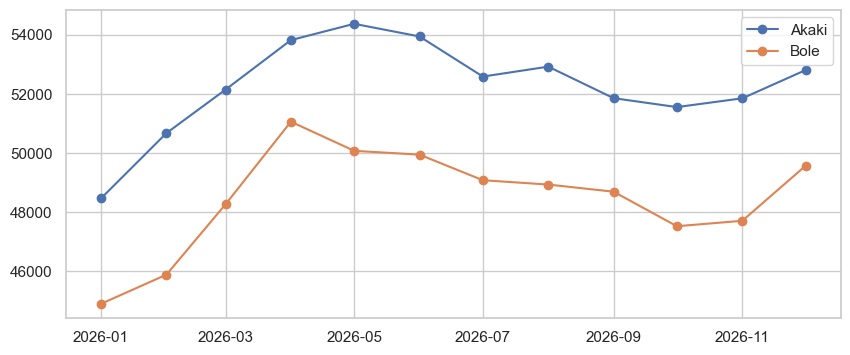

In [15]:
choice = m[m.district.isin(['Bole','Akaki'])]
fig, ax = plt.subplots(figsize=(10, 4))
for name, part in choice.groupby('district'):
    ax.plot(part['month'],
            part['delivered_m3'],
            label=name, marker='o')
ax.legend()
plt.show()

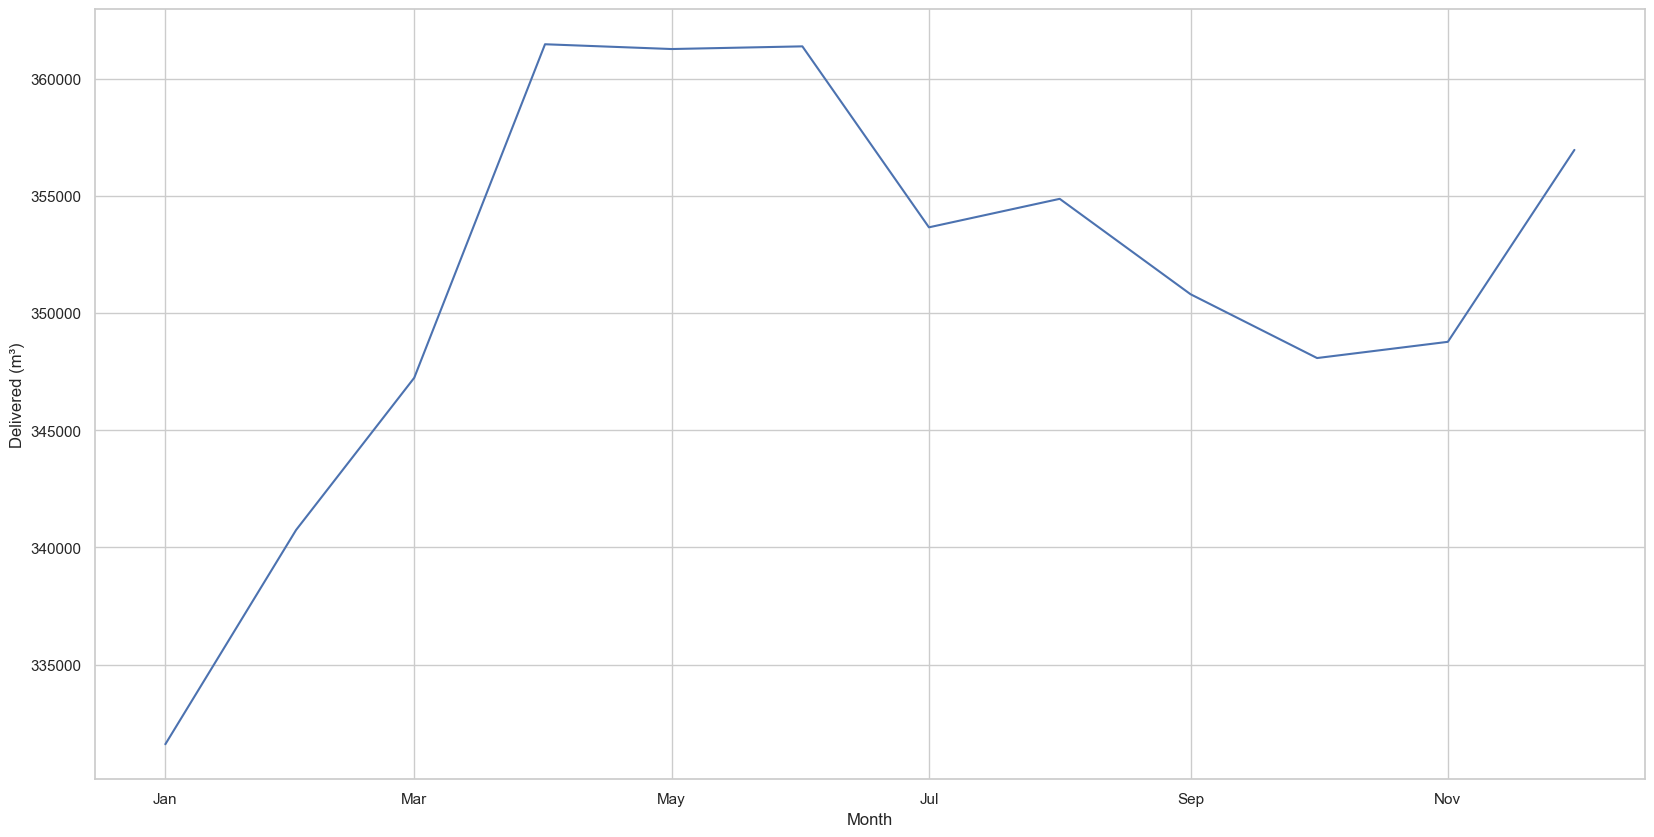

In [20]:
import matplotlib.dates as mdates
fig, ax = plt.subplots(figsize=(20, 10))
ax.plot(trend['month'],
trend['delivered_m3'])
ax.xaxis.set_major_formatter(
mdates.DateFormatter('%b'))
ax.set(xlabel='Month',ylabel='Delivered (m³)')
plt.show()

In [24]:
zone = m.groupby('district')[
'delivered_m3'].sum().sort_values()
print(zone.iloc[:3].to_dict())

{'Bole': 581580, 'Akaki': 626962, 'Kirkos': 669769}


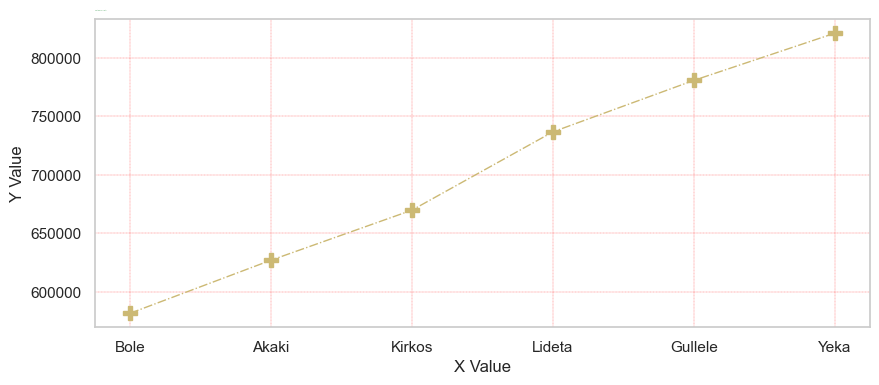

In [127]:
fig, ax = plt.subplots(figsize=(10, 4))
#ax.barh(zone.index, zone.values,color='red' )
#ax.bar(zone.index,zone.values)
#ax.set(xlabel='Delivered water (m³)',ylabel='District')
#ax.grid(axis='x', alpha=0.20)
ax.plot(zone.index, zone.values,marker='P',markersize=10
,linestyle='dashdot',color='y',linewidth=1)#dotted dotted
plt.title(label="Customer Bill data",color='g',size=0.1,loc='left')
plt.xlabel("X Value")
plt.ylabel("Y Value")
plt.grid(color='red',linestyle='--',linewidth=0.2)
#plt.legend()
#plt.annotate(zone.index,zone.values)
plt.annotate("Peak", ('Bole', 6300000))
plt.show()

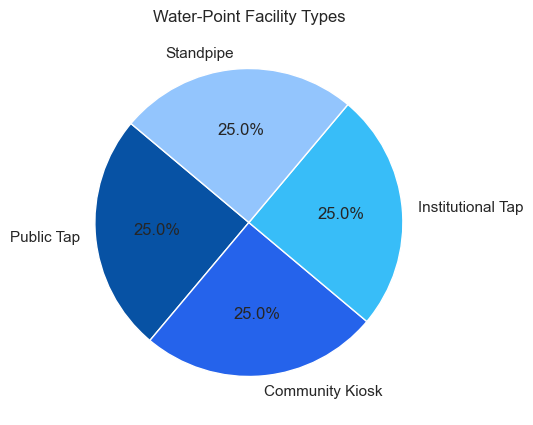

In [104]:
counts = w['point_type'].value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
ax.pie(counts.values, labels=counts.index,
       autopct='%1.1f%%', startangle=140,
       colors=['#0752A4', '#2563EB', '#38BDF8', '#93C5FD'])
ax.set_title('Water-Point Facility Types')
explode=(0, 0, 0.08)
plt.show()